## Midterm Project: Berlin Rental Price Prediction

This is my midterm project for [ML Zoomcamp 2026](https://github.com/DataTalksClub/machine-learning-zoomcamp).

**Problem:** Predict the advertised nightly price of a short-term rental in Berlin using information about the listing, such as its neighbourhood, room type, and accommodation details. This could help compare advertised prices across similar listings.

**Dataset:** [Inside Airbnb — Berlin](https://insideairbnb.com/get-the-data/), summary `listings.csv` (26 June 2026 snapshot). Prices are *advertised nightly prices*, not actual booking transactions.

We will explore the data, train and evaluate regression models, and later deploy the selected model with FastAPI and Docker.

### Part 1: Data Loading and Exploration

In [2]:
# import used libraries
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error

In [3]:
# download the Berlin summary dataset (only once)
data_path = Path('data/listings.csv')
data_path.parent.mkdir(exist_ok=True)

url = 'https://data.insideairbnb.com/germany/be/berlin/2026-06-26/visualisations/listings.csv'

if not data_path.exists():
    pd.read_csv(url).to_csv(data_path, index=False)

# load the data
df = pd.read_csv(data_path)
print('Dataset shape:', df.shape)
df.head()

Dataset shape: (12855, 19)


,id,name,host_id,host_profile_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365,number_of_reviews_ltm,license
0,3176,Fabulous Flat in great Location,3718.0,1.462506e+18,Britta,Pankow,Prenzlauer Berg Südwest,52.53574,13.41734,Entire home/apt,161.0,2.0,150,2025-08-09,0.72,1.0,342,1,First name and Last name: Nicolas Krotz <br/> ...
1,9991,Geourgeous flat - outstanding views,33852.0,1.462507e+18,Philipp,Pankow,Prenzlauer Berg Südwest,52.53269,13.41805,Entire home/apt,193.0,6.0,7,2020-01-04,0.05,1.0,261,0,03/Z/RA/003410-18
2,14325,Studio Apartment in Prenzlauer Berg,55531.0,1.462508e+18,Chris Und Oliver,Pankow,Prenzlauer Berg Nordwest,52.54624,13.40575,Entire home/apt,NaN,180.0,26,2023-11-30,0.13,2.0,211,0,NaN
3,17904,Beautiful Kreuzberg studio - 3 months minimum,68997.0,1.462508e+18,Matthias,Friedrichshain-Kreuzberg,südliche Luisenstadt,52.49626,13.42239,Entire home/apt,11.0,93.0,298,2026-05-31,1.49,1.0,184,2,NaN
4,20858,Designer Loft in Berlin Mitte,71331.0,1.462508e+18,Marc,Pankow,Prenzlauer Berg Südwest,52.53711,13.40888,Entire home/apt,373.0,3.0,145,2026-05-29,0.87,1.0,241,6,03/Z/RA/009767-24


In [4]:
# inspect columns, data types, and missing values
print(df.dtypes)
print('Missing values:')
print(df.isnull().sum())

# check the target column
print('Price examples:')
print(df['price'].head())

id                                  int64
name                                  str
host_id                           float64
host_profile_id                   float64
host_name                             str
neighbourhood_group                   str
neighbourhood                         str
latitude                          float64
longitude                         float64
room_type                             str
price                             float64
minimum_nights                    float64
number_of_reviews                   int64
last_review                           str
reviews_per_month                 float64
calculated_host_listings_count    float64
availability_365                    int64
number_of_reviews_ltm               int64
license                               str
dtype: object
Missing values:
id                                   0
name                                 0
host_id                             79
host_profile_id                     99
host_name       

### Part 2: Data Cleaning and Exploratory Data Analysis

We first remove listings without a valid nightly price. Then we examine the price distribution and compare prices across room types and neighbourhoods.

In [5]:
# remove listings with missing or invalid prices
df_clean = df.dropna(subset=['price']).copy()
df_clean = df_clean[df_clean['price'] > 0].copy()

print('Original shape:', df.shape)
print('Cleaned shape:', df_clean.shape)

# inspect the target distribution
df_clean['price'].describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99])

Original shape: (12855, 19)
Cleaned shape: (8515, 19)


count     8515.000000
mean       160.594950
std        204.185621
min          3.000000
25%         73.000000
50%        131.000000
75%        207.000000
90%        308.000000
95%        385.000000
99%        631.860000
max      10025.000000
Name: price, dtype: float64

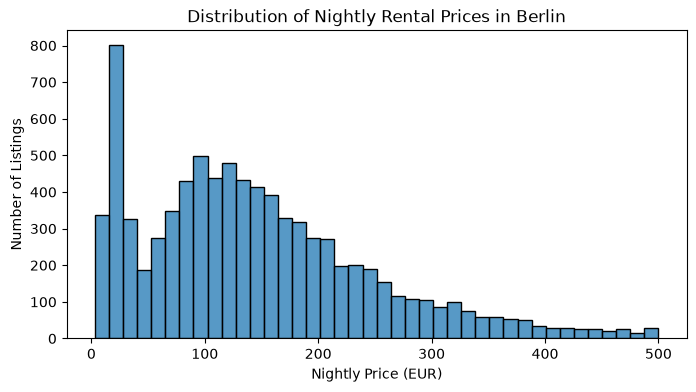

,count,median,mean
room_type,,,
Entire home/apt,6138,156.0,181.44
Hotel room,84,167.5,194.44
Private room,2209,92.0,105.35
Shared room,84,48.0,56.71


In [6]:
# visualize the typical price range (up to 500 EUR)
plt.figure(figsize=(8, 4))
sns.histplot(df_clean.loc[df_clean['price'] <= 500, 'price'], bins=40)
plt.title('Distribution of Nightly Rental Prices in Berlin')
plt.xlabel('Nightly Price (EUR)')
plt.ylabel('Number of Listings')
plt.show()

# compare prices across room types
df_clean.groupby('room_type')['price'].agg(
    ['count', 'median', 'mean']
).round(2)

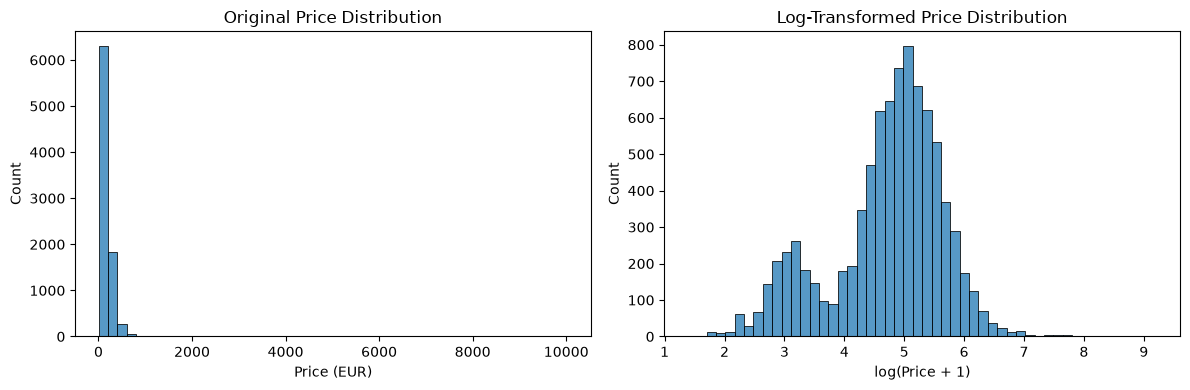

In [9]:
# compare original and log-transformed price distributions
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(df_clean['price'], bins=50, ax=axes[0])
axes[0].set_title('Original Price Distribution')
axes[0].set_xlabel('Price (EUR)')

sns.histplot(np.log1p(df_clean['price']), bins=50, ax=axes[1])
axes[1].set_title('Log-Transformed Price Distribution')
axes[1].set_xlabel('log(Price + 1)')

plt.tight_layout()
plt.show()

The original price distribution is right-skewed, with most listings concentrated at lower prices and a long tail of expensive listings.

Applying `np.log1p()` compresses the higher values and makes the distribution less skewed. We therefore use log-transformed prices
as the target variable during model training.

Predictions will be converted back to euros using `np.expm1()` for evaluation and interpretation.

### Part 3: Feature Selection and Dataset Splitting

The price distribution contains a small number of extreme values. We focus on listings priced at €650 or less, covering approximately 99% of listings with known prices.

We select location, room type, minimum stay, reviews, and availability as predictors. The data is split into training (60%), validation
(20%), and test (20%) sets.

In [7]:
# limit extreme prices
df_model = df_clean[df_clean['price'] <= 650].copy()

# select relevant features
features = [
    'neighbourhood_group',
    'room_type',
    'latitude',
    'longitude',
    'minimum_nights',
    'number_of_reviews',
    'reviews_per_month',
    'availability_365'
]

# keep features and target
df_model = df_model[features + ['price']]

# fill missing numeric feature values
df_model = df_model.fillna(0)

print('Modelling dataset:', df_model.shape)
print('Missing values:', df_model.isnull().sum().sum())

Modelling dataset: (8436, 9)
Missing values: 0


In [10]:
# standardize categorical values (lowercase, replace spaces with underscores)
categorical = ['neighbourhood_group', 'room_type']

for col in categorical:
    df_model[col] = df_model[col].str.lower().str.replace(' ', '_')

df_model.head()

,neighbourhood_group,room_type,latitude,longitude,minimum_nights,number_of_reviews,reviews_per_month,availability_365,price
0,pankow,entire_home/apt,52.53574,13.41734,2.0,150,0.72,342,161.0
1,pankow,entire_home/apt,52.53269,13.41805,6.0,7,0.05,261,193.0
3,friedrichshain-kreuzberg,entire_home/apt,52.49626,13.42239,93.0,298,1.49,184,11.0
4,pankow,entire_home/apt,52.53711,13.40888,3.0,145,0.87,241,373.0
5,mitte,entire_home/apt,52.53316,13.38693,93.0,182,0.98,183,17.0


In [11]:
# split the data into train (60%), validation (20%), and test (20%)
df_full_train, df_test = train_test_split(
    df_model, test_size=0.2, random_state=1
)

df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

# reset indices
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

# get target variable (log transformation)
y_train = np.log1p(df_train.price.values)
y_val = np.log1p(df_val.price.values)
y_test = np.log1p(df_test.price.values)

# remove target to prevent data leakage
del df_train['price']
del df_val['price']
del df_test['price']

# check dataset sizes
print(f"Train, Val, Test: ({len(df_train)}, {len(df_val)}, {len(df_test)})")
print(f"y_train, y_val, y_test: ({len(y_train)}, {len(y_val)}, {len(y_test)})")

df_train.head(3)

Train, Val, Test: (5061, 1687, 1688)
y_train, y_val, y_test: (5061, 1687, 1688)


,neighbourhood_group,room_type,latitude,longitude,minimum_nights,number_of_reviews,reviews_per_month,availability_365
0,neukölln,entire_home/apt,52.465973,13.434565,3.0,20,0.49,193
1,mitte,private_room,52.530180,13.401860,1.0,0,0.00,175
2,pankow,entire_home/apt,52.561190,13.472860,1.0,2,0.77,109


### Part 4: Feature Encoding

We use `DictVectorizer` to one-hot encode categorical variables while keeping numerical features unchanged.
The vectorizer is fitted only on the training data to avoid data leakage.

In [12]:
# convert dataframes to dictionaries
train_dicts = df_train.to_dict(orient='records')
val_dicts = df_val.to_dict(orient='records')
test_dicts = df_test.to_dict(orient='records')

# fit on training data, transform validation and test data
dv = DictVectorizer(sparse=False)

X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)
X_test = dv.transform(test_dicts)

print('Train:', X_train.shape)
print('Validation:', X_val.shape)
print('Test:', X_test.shape)

dv.get_feature_names_out()

Train: (5061, 22)
Validation: (1687, 22)
Test: (1688, 22)


array(['availability_365', 'latitude', 'longitude', 'minimum_nights',
       'neighbourhood_group=charlottenburg-wilm.',
       'neighbourhood_group=friedrichshain-kreuzberg',
       'neighbourhood_group=lichtenberg',
       'neighbourhood_group=marzahn_-_hellersdorf',
       'neighbourhood_group=mitte', 'neighbourhood_group=neukölln',
       'neighbourhood_group=pankow', 'neighbourhood_group=reinickendorf',
       'neighbourhood_group=spandau',
       'neighbourhood_group=steglitz_-_zehlendorf',
       'neighbourhood_group=tempelhof_-_schöneberg',
       'neighbourhood_group=treptow_-_köpenick', 'number_of_reviews',
       'reviews_per_month', 'room_type=entire_home/apt',
       'room_type=hotel_room', 'room_type=private_room',
       'room_type=shared_room'], dtype=object)

### Part 5: Model Training and Evaluation

We start with Linear Regression as a baseline model.

The model predicts log-transformed prices. We evaluate its performance using RMSE on the validation dataset, both in log space and in euros.

We will then compare it with tree-based models.

In [13]:
# train baseline model
lr = LinearRegression()
lr.fit(X_train, y_train)

# predict log-prices on validation data
y_pred = lr.predict(X_val)

# calculate RMSE in log space
rmse_log = np.sqrt(mean_squared_error(y_val, y_pred))

# convert predictions and actual values back to euros
y_pred_eur = np.expm1(y_pred)
y_val_eur = np.expm1(y_val)

# calculate errors in euros
rmse_eur = np.sqrt(mean_squared_error(y_val_eur, y_pred_eur))
mae_eur = mean_absolute_error(y_val_eur, y_pred_eur)

print(f'Linear Regression - RMSE (log): {rmse_log:.4f}')
print(f'Linear Regression - RMSE (EUR): {rmse_eur:.2f}')
print(f'Linear Regression - MAE (EUR): {mae_eur:.2f}')

Linear Regression - RMSE (log): 0.4680
Linear Regression - RMSE (EUR): 85.23
Linear Regression - MAE (EUR): 52.31


### Part 6: Decision Tree Regression

We train a Decision Tree Regressor and tune its maximum depth.

Different tree depths are evaluated on the validation dataset using RMSE. This helps us find a suitable balance between underfitting and overfitting.

In [14]:
# test different maximum tree depths
for depth in [3, 5, 7, 10, 15, 20]:
    dt = DecisionTreeRegressor(max_depth=depth, random_state=1)
    dt.fit(X_train, y_train)

    y_pred = dt.predict(X_val)

    rmse_log = np.sqrt(mean_squared_error(y_val, y_pred))
    rmse_eur = np.sqrt(
        mean_squared_error(np.expm1(y_val), np.expm1(y_pred))
    )

    print(f'Depth {depth:2d}: RMSE (log) = {rmse_log:.4f}, RMSE (EUR) = {rmse_eur:.2f}')

Depth  3: RMSE (log) = 0.4648, RMSE (EUR) = 87.62
Depth  5: RMSE (log) = 0.4541, RMSE (EUR) = 86.70
Depth  7: RMSE (log) = 0.4562, RMSE (EUR) = 85.64
Depth 10: RMSE (log) = 0.4591, RMSE (EUR) = 85.37
Depth 15: RMSE (log) = 0.5081, RMSE (EUR) = 93.65
Depth 20: RMSE (log) = 0.5466, RMSE (EUR) = 104.57
